# What LightGBM regularizers keep and `linear_tree` loses

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/firefly1248/demo-notebooks/blob/main/notebooks/lightgbm/lightgbm_linear_tree_regularizers.ipynb)

LightGBM's regularizers change how trees grow, but every leaf stays a constant. `linear_tree=True`
puts a linear model in each leaf instead. This notebook checks two properties that constant
leaves give for free, across the regularizers and with `linear_tree`:

1. **Exact TreeSHAP.** `predict(pred_contrib=True)` should sum to the raw score.
2. **Monotone constraints.** With `monotone_constraints=[1, 0, 0]` the prediction should never
   go down as `x0` goes up.

Everything runs on a toy with a known shape, on the versions pinned in the first cell. Under a
minute on a laptop CPU, several times that on a free Colab CPU.

In [1]:
from importlib.metadata import version, PackageNotFoundError

def installed(package, pin):
    try:
        return version(package) == pin
    except PackageNotFoundError:
        return False

if not all(installed(p, v) for p, v in (("lightgbm", "4.7.0"), ("shap", "0.53.0"))):
    !pip install -q lightgbm==4.7.0 shap==0.53.0

In [2]:
import numpy as np, pandas as pd, lightgbm as lgb, shap
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
print("lightgbm", lgb.__version__, "shap", shap.__version__)

lightgbm 4.7.0 shap 0.53.0


## Data and configurations

`y = x0 + 2 sin(x1) + 0.5 x2 + noise`, three uniform features on [0, 10], noise sd 2. The truth
increases in `x0`, so the increasing constraint on `x0` is correct. Every fit carries it, and each
configuration adds one regularizer to the same base. `linear_lambda` is `linear_tree`'s own L2
penalty on leaf coefficients.

In [3]:
N, SEEDS, N_ROWS, TOL = 1500, range(3), 200, 1e-9
GRID = np.linspace(0, 10, 400)
BASE = dict(n_estimators=200, learning_rate=0.1, num_leaves=15, verbose=-1, monotone_constraints=[1, 0, 0])

CONFIGS = {
    "baseline": {},
    "reg_lambda=10": dict(reg_lambda=10),
    "path_smooth=10": dict(path_smooth=10),
    "min_child_samples=50": dict(min_child_samples=50),
    "max_depth=3": dict(max_depth=3, num_leaves=8),
    "subsample+colsample 0.7": dict(subsample=0.7, subsample_freq=1, colsample_bytree=0.7),
    "extra_trees=True": dict(extra_trees=True),
    "boosting=dart": dict(boosting_type="dart"),
    "goss": dict(data_sample_strategy="goss"),
    "linear_tree=True": dict(linear_tree=True),
    "linear_tree + linear_lambda=10": dict(linear_tree=True, linear_lambda=10),
}

def make_data(seed):
    rng = np.random.RandomState(seed)
    X = rng.uniform(0, 10, (N, 3))
    y = X[:, 0] + 2 * np.sin(X[:, 1]) + 0.5 * X[:, 2] + rng.normal(0, 2.0, N)
    return X, y

## Two checks

**Additivity.** The largest absolute gap between the row sum of `pred_contrib` (contributions plus
the bias column) and the raw score. LightGBM refuses `pred_contrib` on linear trees, so those
configurations skip this check here; the next section shows the refusal.

**Monotonicity.** Sweep `x0` over a grid for the first 200 training rows, other features fixed.
A step between neighbouring grid points below `-1e-9` is a violation.

In [4]:
def additivity_gap(model, X):
    if model.get_params().get("linear_tree"):
        return np.nan
    contrib = model.predict(X, pred_contrib=True).sum(1)
    return np.abs(contrib - model.predict(X, raw_score=True)).max()

def sweep_rows(X):
    rows = np.repeat(X[:N_ROWS], len(GRID), axis=0)
    rows[:, 0] = np.tile(GRID, N_ROWS)
    return rows

def grid_steps(model, X):
    return np.diff(model.predict(sweep_rows(X)).reshape(N_ROWS, len(GRID)), axis=1)

records, seed0 = [], {}
for name, kw in CONFIGS.items():
    for seed in SEEDS:
        X, y = make_data(seed)
        model = lgb.LGBMRegressor(**{**BASE, "random_state": seed, **kw}).fit(X, y)
        if seed == 0:
            seed0[name] = model
        steps = grid_steps(model, X)
        down = steps < -TOL
        records.append(dict(config=name, seed=seed, gap=additivity_gap(model, X), rows_down=down.any(1).mean(),
                            steps_down=down.mean(), worst_step=steps.min()))
runs = pd.DataFrame(records)

## Results

One line per configuration over three seeds.

In [5]:
runs.groupby("config", sort=False).agg(
    max_additivity_gap=("gap", "max"),
    rows_with_a_down_step=("rows_down", "mean"),
    down_steps_min=("steps_down", "min"),
    down_steps_max=("steps_down", "max"),
    worst_step=("worst_step", "min"),
).style.format({"max_additivity_gap": "{:.1e}", "rows_with_a_down_step": "{:.0%}",
                "down_steps_min": "{:.1%}", "down_steps_max": "{:.1%}", "worst_step": "{:.3f}"},
               na_rep="refused")

,max_additivity_gap,rows_with_a_down_step,down_steps_min,down_steps_max,worst_step
config,,,,,
baseline,2.8e-14,0%,0.0%,0.0%,0.000
reg_lambda=10,4.1e-14,0%,0.0%,0.0%,0.000
path_smooth=10,3.9e-14,0%,0.0%,0.0%,0.000
min_child_samples=50,3.6e-14,0%,0.0%,0.0%,0.000
max_depth=3,5.3e-14,0%,0.0%,0.0%,0.000
subsample+colsample 0.7,3.9e-14,0%,0.0%,0.0%,0.000
extra_trees=True,2.8e-14,0%,0.0%,0.0%,0.000
boosting=dart,3.5e-14,0%,0.0%,0.0%,0.000
goss,4.6e-14,0%,0.0%,0.0%,0.000


Every configuration with constant leaves passes both checks: the contributions add up to the raw
score to floating-point error, and no row has a single down step. That includes the ones that
randomize splits (`extra_trees`), drop trees (`dart`) or reweight rows (`goss`): they change which
trees get built, while every leaf stays a constant.

With `linear_tree` every row goes down somewhere. `linear_lambda` cuts the share of down steps but
does not remove them.

## LightGBM and the shap library refuse TreeSHAP on linear trees

`shap.TreeExplainer` gets the same `LightGBMError`. The stderr lines are LightGBM's own log.

In [6]:
X, y = make_data(0)
linear, constant = seed0["linear_tree=True"], seed0["baseline"]
for label, call in (("pred_contrib", lambda: linear.predict(X[:5], pred_contrib=True)),
                    ("shap.TreeExplainer", lambda: shap.TreeExplainer(linear).shap_values(X[:5]))):
    try:
        call()
    except Exception as error:
        print(f"{label}: {type(error).__name__}: {error}")

pred_contrib: LightGBMError: Predicting SHAP feature contributions is not implemented for linear trees.
shap.TreeExplainer: LightGBMError: Predicting SHAP feature contributions is not implemented for linear trees.


[LightGBM] [Fatal] Predicting SHAP feature contributions is not implemented for linear trees.
[LightGBM] [Fatal] Predicting SHAP feature contributions is not implemented for linear trees.


## Where the down steps come from

Along the `x0` sweep a step between neighbouring grid points is one of two kinds. If the row stays
in the same leaf of every tree, the prediction is a sum of linear functions of `x0` over that
step, and its slope is the sum of the leaf coefficients on `x0`. If the row moves to another leaf
in at least one tree, the two leaf models need not meet at the split, and the prediction can jump.

`pred_leaf=True` tells the two apart. The table splits the down steps of the seed-0 `linear_tree`
fit by kind.

In [7]:
leaves = linear.predict(sweep_rows(X), pred_leaf=True).reshape(N_ROWS, len(GRID), -1)
same_leaves = (leaves[:, 1:] == leaves[:, :-1]).all(-1)

steps = grid_steps(linear, X)
down = steps < -TOL
pd.DataFrame([
    {"step": kind, "steps": mask.sum(), "down steps": (down & mask).sum(),
     "share that go down": f"{down[mask].mean():.1%}",
     "median drop": round(-np.median(steps[down & mask]), 4),
     "largest drop": round(-steps[down & mask].min(), 3)}
    for kind, mask in (("same leaves", same_leaves), ("leaf change", ~same_leaves))
]).set_index("step")

,steps,down steps,share that go down,median drop,largest drop
step,,,,,
same leaves,70875,20728,29.2%,0.0189,0.381
leaf change,8925,1236,13.8%,0.0701,0.838


Most down steps happen with the row in the same leaves, where the prediction slides down along a
straight line: the constraint does not restrict the coefficients a linear leaf fits. Leaf changes
are fewer but give the largest drops.

## One row along `x0`

The row with the largest single drop in the seed-0 `linear_tree` fit, so its dips are larger than
a typical row's. The constant-leaf fit on the same data is a staircase that never steps down.

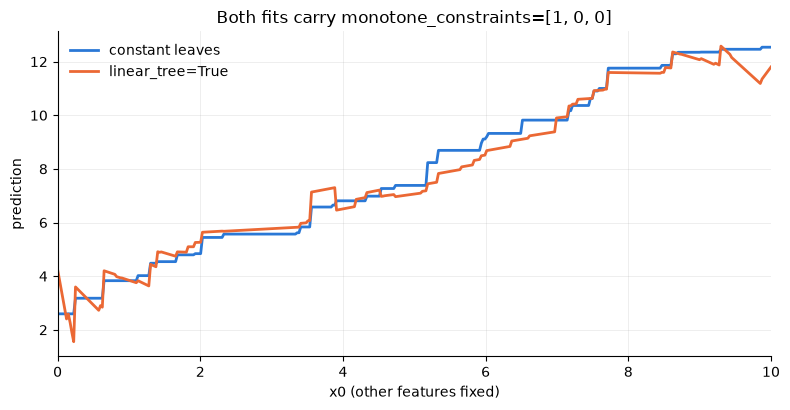

In [8]:
row = X[steps.min(1).argmin()].copy()
sweep = np.tile(row, (len(GRID), 1))
sweep[:, 0] = GRID

fig, ax = plt.subplots(figsize=(8, 4.2))
fig.patch.set_facecolor("white")
for model, label, color in ((constant, "constant leaves", "#2a78d6"), (linear, "linear_tree=True", "#eb6834")):
    ax.plot(GRID, model.predict(sweep), color=color, lw=2, label=label)
ax.set(xlabel="x0 (other features fixed)", ylabel="prediction", xlim=(0, 10),
       title="Both fits carry monotone_constraints=[1, 0, 0]")
ax.legend(frameon=False, loc="upper left")
ax.grid(alpha=0.25, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("lightgbm_linear_tree_monotone.png", dpi=150, facecolor="white")
plt.show()

## Takeaways

- Every regularizer tested, `dart` and `goss` included, keeps exact TreeSHAP and the monotone
  guarantee.
- `linear_tree` loses both: TreeSHAP is refused, and the constraint breaks inside leaves and at
  leaf changes. `linear_lambda` reduces the violations without removing them.
- If SHAP values go into an audit or a monotone shape into a contract, keep leaves constant.
- A matching sum is an additivity check, not proof that the attributions are right. The toy has
  three features and three seeds.